<img src="../Imagenes/logo-final-ap.png" width="85" align="left"/>

# <span style="color:#bd232b">Aprendizaje Profundo</span>

[https://github.com/AprendizajeProfundo](https://github.com/AprendizajeProfundo)

# <span style="color:#174ea6">Cuaderno 102 · Q-learning y Deep Q-Networks (DQN)</span>

**Sesión 1 · De las decisiones tabulares al aprendizaje profundo y Hydro-Lab**

**Autores:** Álvaro Montenegro · Daniel Montenegro · Pilar Montenegro  
**Docente:** Álvaro Montenegro, [ammontenegrod@gmail.com](mailto:ammontenegrod@gmail.com),  
**Institución:** Universidad de los Andes - Ecopetrol  
**Edición docente:** 102 · Octubre de 2026  
**Licencia del material original de esta edición:** MIT (véase sección final).  

> **Pregunta rectora.** ¿Cómo puede un agente aprender el valor de sus decisiones sin conocer las probabilidades de transición, y qué cambia cuando la tabla de valores debe ser sustituida por una red neuronal?

**Fuentes directas de reelaboración:** `14_ar_Q_Learning-02.ipynb` (Q-learning), `09_ar_DQN_Learning-ver-02.ipynb` (DQN y CartPole), `05_ar_OpenAI_Gym_CartPole.ipynb` (entorno y observaciones). `10_ar_DQN_Learning-Pong.ipynb` se utiliza solo como referencia de extensión. Se preservan todos los originales.

## <span style="color:#bd232b">Guía de navegación y resultados de aprendizaje</span>

**Tiempo orientativo de clase: 60 minutos.** Las demostraciones largas, la ejecución completa de DQN y los ejercicios de ampliación pueden realizarse después de la sesión.

| Bloque | Minutos | Resultado observable |
|---|---:|---|
| Recuperar Bellman y aprender sin modelo | 0–10 | Identificar el error de diferencia temporal |
| Q-learning tabular en una cuadrícula | 10–25 | Tabla Q, trayectoria aprendida y curva de retorno |
| Aproximación de Q mediante redes neuronales | 25–35 | Explicar replay y red objetivo |
| CartPole con DQN | 35–50 | Implementación reproducible y evaluación |
| Hydro-Lab: límites de DQN y puente a políticas | 50–60 | Argumentar la elección del algoritmo |

**Al terminar**, el estudiante podrá (i) derivar Q-learning desde Bellman, (ii) diferenciar *on-policy* de *off-policy*, (iii) construir un agente tabular, (iv) explicar y programar DQN, (v) evaluar políticas sin confundir aprendizaje y evaluación, y (vi) reconocer por qué Hydro-Lab presenta un problema de acciones continuas.

## <span style="color:#bd232b">1. Del MDP al aprendizaje sin conocer el modelo</span>

En el **101** calculamos valores cuando se conocen las transiciones $P(s'\mid s,a)$ y las recompensas. En muchos problemas, esas probabilidades son desconocidas, pero podemos **interactuar con el entorno** y observar transiciones $(s_t,a_t,r_{t+1},s_{t+1})$.

El valor óptimo de una acción satisface la ecuación de optimalidad de Bellman:

$$
Q^*(s,a)=\mathbb{E}\left[R_{t+1}+\gamma\max_{a'}Q^*(S_{t+1},a')\mid S_t=s,A_t=a\right].
$$

**Q-learning** reemplaza la esperanza por una muestra y actualiza una estimación:

$$
\boxed{Q(s_t,a_t)\leftarrow Q(s_t,a_t)+\alpha\underbrace{\left[r_{t+1}+\gamma(1-d_t)\max_{a'}Q(s_{t+1},a')-Q(s_t,a_t)\right]}_{\delta_t\,\text{: error TD}}}
$$

Aquí $d_t=1$ indica un **estado terminal real**; $\alpha$ es la tasa de aprendizaje y $\gamma$ descuenta recompensas futuras. Para un episodio truncado por un límite artificial de tiempo, el tratamiento del *bootstrap* requiere distinguir truncamiento de terminación; volveremos a ello con CartPole.

**Lectura de la ecuación:** predicción anterior $\to$ objetivo observado $\to$ error $\to$ corrección.

### 1.1 Exploración, explotación y aprendizaje *off-policy*

La política $\varepsilon$-greedy elige una acción aleatoria con probabilidad $\varepsilon$ y, en otro caso, una acción de máximo valor estimado. Q-learning es **off-policy**: puede explorar con $\varepsilon$-greedy mientras su objetivo utiliza $\max_{a'}Q(s',a')$, que corresponde a una política voraz distinta.

En un MDP finito, bajo condiciones apropiadas de visitas suficientes y tasas de aprendizaje decrecientes, Q-learning converge al valor óptimo. **No** se debe trasladar automáticamente esta garantía al caso con aproximación neuronal.

<img src="../Imagenes/MDP.png" width="540"/>

*Figura 102.1. Diagrama MDP reutilizado de la colección original; se mantiene su ruta en el repositorio.*

## <span style="color:#bd232b">2. Laboratorio tabular: una cuadrícula con obstáculos</span>

Usaremos una cuadrícula de $5\times5$. El agente comienza en la esquina superior izquierda y debe alcanzar la meta inferior derecha. Algunas celdas están bloqueadas. Cada paso tiene un pequeño costo y llegar a la meta proporciona una recompensa positiva. El ejemplo está inspirado en la tradición de FrozenLake/GridWorld de los cuadernos originales, pero aquí construimos una versión **determinista y autocontenida** para ver cada operación de Q-learning.

**Estado:** posición $(fila,columna)$, codificada como un entero. **Acciones:** arriba, derecha, abajo e izquierda. **Episodio:** termina en la meta o al alcanzar un límite pedagógico de pasos. El límite de pasos se usa para detener la simulación, no para definir un estado terminal del MDP.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

SEMILLA = 2026
np.random.seed(SEMILLA)

class Cuadricula:
    movimientos = [(-1, 0), (0, 1), (1, 0), (0, -1)]
    nombres_accion = ['↑', '→', '↓', '←']

    def __init__(self, tam=5, obstaculos=((1, 1), (1, 2), (3, 1), (3, 3))):
        self.tam = tam
        self.obstaculos = set(obstaculos)
        self.inicio = (0, 0)
        self.meta = (tam - 1, tam - 1)
        self.n_estados = tam * tam
        self.n_acciones = 4
        assert self.inicio not in self.obstaculos and self.meta not in self.obstaculos
        self.pos = self.inicio

    def codificar(self, pos):
        return pos[0] * self.tam + pos[1]

    def decodificar(self, s):
        return divmod(int(s), self.tam)

    def reset(self):
        self.pos = self.inicio
        return self.codificar(self.pos)

    def step(self, accion):
        dr, dc = self.movimientos[int(accion)]
        candidata = (self.pos[0] + dr, self.pos[1] + dc)
        if (0 <= candidata[0] < self.tam and 0 <= candidata[1] < self.tam
                and candidata not in self.obstaculos):
            self.pos = candidata
        terminado = self.pos == self.meta
        recompensa = 1.0 if terminado else -0.02
        return self.codificar(self.pos), recompensa, terminado

entorno = Cuadricula()
print(f'Estados: {entorno.n_estados} | Acciones: {entorno.n_acciones}')
print('Inicio:', entorno.inicio, '| Meta:', entorno.meta, '| Obstáculos:', sorted(entorno.obstaculos))

Estados: 25 | Acciones: 4
Inicio: (0, 0) | Meta: (4, 4) | Obstáculos: [(1, 1), (1, 2), (3, 1), (3, 3)]


### 2.1 Implementar Q-learning sin ocultar el algoritmo

La tabla $Q\in\mathbb{R}^{25\times4}$ contiene un valor por estado y acción. En cada transición: elegimos acción, observamos la recompensa, calculamos el objetivo TD y actualizamos **una sola entrada** de la tabla. Para que las comparaciones sean reproducibles, la exploración utiliza un generador aleatorio explícito.

Usaremos $\varepsilon$ decreciente y una tasa $\alpha$ constante como configuración pedagógica. Esto permite observar aprendizaje rápido, pero **no constituye por sí solo una demostración de convergencia asintótica**.

In [2]:
def seleccionar_accion(q, estado, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(q.shape[1]))
    maximo = q[estado].max()
    candidatas = np.flatnonzero(np.isclose(q[estado], maximo))
    return int(rng.choice(candidatas))

def entrenar_q_tabular(n_episodios=1800, alpha=0.25, gamma=0.97,
                      epsilon_inicial=1.0, epsilon_final=0.05, max_pasos=90,
                      semilla=SEMILLA):
    env = Cuadricula()
    q = np.zeros((env.n_estados, env.n_acciones), dtype=float)
    rng = np.random.default_rng(semilla)
    retornos, exitos, epsilons = [], [], []
    for episodio in range(n_episodios):
        epsilon = epsilon_final + (epsilon_inicial - epsilon_final) * np.exp(-episodio / 320)
        s = env.reset()
        total, exito = 0.0, False
        for paso in range(max_pasos):
            a = seleccionar_accion(q, s, epsilon, rng)
            siguiente, r, terminado = env.step(a)
            objetivo = r + gamma * (0.0 if terminado else np.max(q[siguiente]))
            q[s, a] += alpha * (objetivo - q[s, a])
            s, total = siguiente, total + r
            if terminado:
                exito = True
                break
        retornos.append(total)
        exitos.append(int(exito))
        epsilons.append(epsilon)
    return q, np.asarray(retornos), np.asarray(exitos), np.asarray(epsilons)

q_tabular, retornos_q, exitos_q, eps_q = entrenar_q_tabular()
print('Éxito últimos 200 episodios:', f'{exitos_q[-200:].mean():.1%}')
print('Retorno medio últimos 200 episodios:', f'{retornos_q[-200:].mean():.3f}')

Éxito últimos 200 episodios: 100.0%
Retorno medio últimos 200 episodios: 0.851


### 2.2 ¿Aprendió una política útil?

No basta con mostrar la recompensa de un episodio afortunado. Visualizamos una **media móvil** y la trayectoria de una política voraz independiente de la exploración. En esta cuadrícula determinista, la evaluación voraz permite comprobar si el agente llega a la meta sin pasos innecesarios.

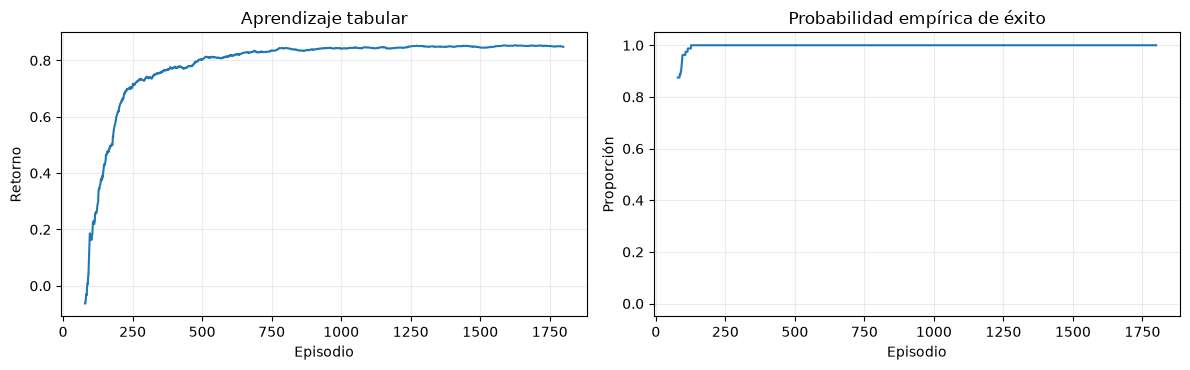

In [3]:
def media_movil(x, ventana=80):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(ventana) / ventana, mode='valid')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(np.arange(79, len(retornos_q)), media_movil(retornos_q), label='Retorno medio (80 episodios)')
ax[0].set(xlabel='Episodio', ylabel='Retorno', title='Aprendizaje tabular')
ax[0].grid(alpha=0.25)
ax[1].plot(np.arange(79, len(exitos_q)), media_movil(exitos_q), label='Éxito (80 episodios)')
ax[1].set(xlabel='Episodio', ylabel='Proporción', ylim=(-0.05, 1.05), title='Probabilidad empírica de éxito')
ax[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

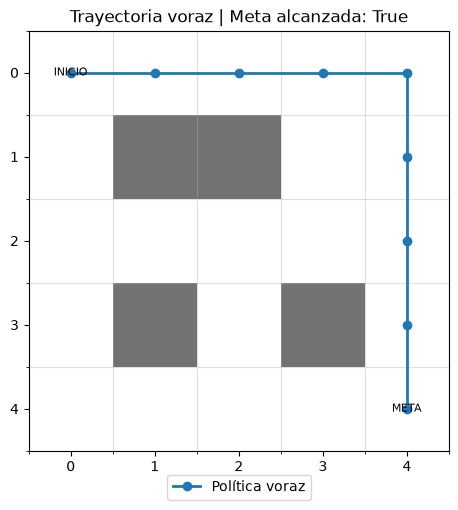

Pasos: 8 | Secuencia: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (4, 4)]


In [4]:
def trayectoria_voraz(q, max_pasos=40):
    env = Cuadricula()
    s = env.reset()
    recorrido = [env.pos]
    for _ in range(max_pasos):
        a = int(np.argmax(q[s]))
        s, _, terminado = env.step(a)
        recorrido.append(env.pos)
        if terminado:
            break
    return recorrido, env.pos == env.meta

recorrido, exito_voraz = trayectoria_voraz(q_tabular)
fig, ax = plt.subplots(figsize=(5.2, 5.2))
mapa = np.zeros((5, 5))
for fila, col in entorno.obstaculos:
    mapa[fila, col] = 1
ax.imshow(mapa, cmap='Greys', vmin=0, vmax=1.6)
ax.set_xticks(range(5)); ax.set_yticks(range(5))
ax.set_xticks(np.arange(-.5, 5, 1), minor=True)
ax.set_yticks(np.arange(-.5, 5, 1), minor=True)
ax.grid(which='minor', alpha=0.4)
xs = [p[1] for p in recorrido]
ys = [p[0] for p in recorrido]
ax.plot(xs, ys, '-o', linewidth=2, label='Política voraz')
ax.text(0, 0, 'INICIO', ha='center', va='center', fontsize=8)
ax.text(4, 4, 'META', ha='center', va='center', fontsize=8)
ax.set_title(f'Trayectoria voraz | Meta alcanzada: {exito_voraz}')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(); plt.show()
print('Pasos:', len(recorrido)-1, '| Secuencia:', recorrido)

### 2.3 Comprobaciones, límites y discusión

- **¿Por qué no basta una tabla Q?** Para $10^6$ estados y $20$ acciones necesitaríamos veinte millones de entradas; con observaciones continuas hay infinitos estados posibles en el modelo matemático.
- **¿Qué significa generalizar?** Aprovechar lo aprendido en estados parecidos para estimar valores en estados no visitados.
- **¿Por qué no basta discretizar siempre?** El número de celdas crece exponencialmente con el número de dimensiones (*maldición de la dimensionalidad*).

La transición a DQN consiste en sustituir la tabla por una función parametrizada $Q_\theta(s,a)$, pero esto introduce problemas de estabilidad y sesgo que no existían del mismo modo en la versión tabular.

## <span style="color:#bd232b">3. De Q-learning a Deep Q-Networks</span>

Una red neuronal aproxima los valores de todas las acciones discretas para una observación $s$:

$$
Q_\theta(s,\cdot)=\bigl(Q_\theta(s,a_1),\ldots,Q_\theta(s,a_m)\bigr).
$$

El objetivo de regresión de DQN es

$$
y_i=r_i+\gamma(1-d_i)\max_{a'}Q_{\theta^-}(s_i',a'),
\qquad
\mathcal{L}(\theta)=\frac1B\sum_{i=1}^B\bigl(Q_\theta(s_i,a_i)-y_i\bigr)^2.
$$

Aquí $\theta^-$ representa una **red objetivo** que se actualiza menos frecuentemente. Las transiciones $(s,a,r,s',d)$ se guardan en un **buffer de experiencias** (*experience replay*); el entrenamiento toma minibatches aleatorios para reducir correlaciones temporales.

<img src="../Imagenes/deep_Q_learning.png" width="700"/>

*Figura 102.2. Arquitectura de Deep Q-learning reutilizada del cuaderno 09.*

### 3.1 Tres mecanismos que conviene distinguir

**Red principal:** se entrena con descenso por gradiente. **Red objetivo:** proporciona un objetivo temporalmente más estable; no recibe gradientes durante cada actualización. **Replay buffer:** conserva transiciones de distintos momentos y permite reutilizarlas.

El algoritmo DQN básico, presentado en el trabajo de Mnih y colaboradores, puede resumirse así:

1. Inicializar la red principal, copiar sus pesos a la red objetivo y crear el buffer.
2. Interactuar con el entorno usando $\varepsilon$-greedy y guardar transiciones.
3. Muestrear minibatches del buffer y calcular los objetivos TD con la red objetivo.
4. Actualizar la red principal por gradiente y sincronizar periódicamente la red objetivo.
5. Evaluar por separado con exploración desactivada.

**Limitación central:** el DQN estándar supone un **conjunto finito y discreto de acciones**. El operador $\max_a$ no se puede aplicar por simple enumeración a todas las consignas continuas de tres bombas.

## <span style="color:#bd232b">4. CartPole: el puente entre un MDP sencillo y el control</span>

<img src="../Imagenes/Ejemplo_polea.gif" width="450"/>

*Figura 102.3. Ejemplo animado de CartPole, reutilizado del cuaderno 05.*

En `CartPole-v1`, un carro se desplaza horizontalmente y debe mantener un péndulo invertido. La observación contiene **cuatro números continuos**: posición y velocidad del carro, ángulo y velocidad angular del péndulo. Las acciones son **dos fuerzas discretas**: izquierda o derecha.

Es un entorno ideal para DQN porque tiene **observaciones continuas pero acciones discretas**. Esa distinción es fundamental: DQN no requiere estados discretos, pero sí un conjunto discreto y enumerable de acciones.

En Gymnasium, `step()` devuelve `(observacion, recompensa, terminated, truncated, info)`. `terminated` señala una terminación propia del entorno; `truncated` indica, por ejemplo, el límite de duración. Para el objetivo de DQN se anula el *bootstrap* al terminar, **no simplemente por truncar**.

### 4.1 Preparación del entorno

El bloque tabular solo requiere `numpy` y `matplotlib`. Para ejecutar la parte DQN de CartPole instala, si es necesario:

```bash
python -m pip install 'gymnasium[classic-control]' torch numpy matplotlib
```

En un Mac Apple Silicon, PyTorch puede utilizar MPS si está disponible. El ejemplo utiliza CPU por defecto para facilitar la reproducibilidad y evitar diferencias entre dispositivos. Si Gymnasium no está instalado, el cuaderno **no falla**: informa qué falta y permite continuar con las secciones conceptuales.

In [5]:
import importlib.util
import torch
from torch import nn
import torch.nn.functional as F

GYM_DISPONIBLE = importlib.util.find_spec('gymnasium') is not None
if GYM_DISPONIBLE:
    import gymnasium as gym
    env_demo = gym.make('CartPole-v1')
    observacion, info = env_demo.reset(seed=SEMILLA)
    print('CartPole-v1:', env_demo.observation_space, env_demo.action_space)
    print('Observación inicial:', np.round(observacion, 3))
    env_demo.close()
else:
    print('Gymnasium no está instalado. Para ejecutar DQN: pip install "gymnasium[classic-control]"')
print('PyTorch:', torch.__version__)

CartPole-v1: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32) Discrete(2)
Observación inicial: [-0.032  0.014 -0.003 -0.013]
PyTorch: 2.14.1


### 4.2 Red Q, buffer y selección de acciones

La arquitectura utiliza dos capas ocultas de 64 unidades con activación ReLU y dos salidas, una por acción. La función de pérdida será **Huber** (*smooth L1*), más robusta a errores TD extremos que el error cuadrático puro.

El buffer conserva `terminated` separado de `truncated` para que el objetivo TD haga *bootstrap* cuando el episodio solo se interrumpe por el límite de tiempo. Los dos casos obligan a reiniciar el entorno para iniciar un nuevo episodio.

In [6]:
class RedQ(nn.Module):
    def __init__(self, n_observaciones=4, n_acciones=2):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(n_observaciones, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, n_acciones),
        )

    def forward(self, x):
        return self.red(x)

class BufferExperiencias:
    def __init__(self, capacidad=20_000):
        self.datos = deque(maxlen=capacidad)

    def agregar(self, estado, accion, recompensa, siguiente, terminado):
        self.datos.append((np.asarray(estado, dtype=np.float32).copy(),
                           int(accion), float(recompensa),
                           np.asarray(siguiente, dtype=np.float32).copy(),
                           bool(terminado)))

    def muestra(self, tam, rng):
        indices = rng.choice(len(self.datos), size=tam, replace=False)
        lote = [self.datos[int(i)] for i in indices]
        s, a, r, sp, terminal = zip(*lote)
        return (torch.as_tensor(np.asarray(s)),
                torch.as_tensor(a, dtype=torch.int64),
                torch.as_tensor(r, dtype=torch.float32),
                torch.as_tensor(np.asarray(sp)),
                torch.as_tensor(terminal, dtype=torch.float32))

    def __len__(self):
        return len(self.datos)

red_prueba = RedQ()
assert red_prueba(torch.zeros(3, 4)).shape == (3, 2)
print('Parámetros de la red:', sum(p.numel() for p in red_prueba.parameters()))

Parámetros de la red: 4610


### 4.3 Actualización DQN: un paso de gradiente

La selección de acciones y el entrenamiento son funciones distintas. El objetivo TD se calcula dentro de `torch.no_grad()` para que el gradiente no atraviese la red objetivo.

En este ejemplo utilizamos **DQN clásico**, no Double DQN ni Dueling DQN. Esta delimitación permite entender exactamente qué hace cada componente antes de estudiar mejoras.

In [7]:
def accion_dqn(red, estado, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(2))
    with torch.no_grad():
        x = torch.as_tensor(np.asarray(estado, dtype=np.float32)).unsqueeze(0)
        return int(red(x).argmax(dim=1).item())

def paso_dqn(red, red_objetivo, optimizador, buffer, rng,
             lote=64, gamma=0.99):
    estados, acciones, recompensas, siguientes, terminales = buffer.muestra(lote, rng)
    predicciones = red(estados).gather(1, acciones[:, None]).squeeze(1)
    with torch.no_grad():
        maximos_siguientes = red_objetivo(siguientes).max(dim=1).values
        objetivos = recompensas + gamma * (1.0 - terminales) * maximos_siguientes
    perdida = F.smooth_l1_loss(predicciones, objetivos)
    optimizador.zero_grad()
    perdida.backward()
    torch.nn.utils.clip_grad_norm_(red.parameters(), max_norm=10.0)
    optimizador.step()
    return float(perdida.item())

# Prueba unitaria mínima, independiente de Gymnasium.
rng_prueba = np.random.default_rng(123)
buffer_prueba = BufferExperiencias()
for i in range(80):
    buffer_prueba.agregar(np.ones(4)*i/80, i%2, 1.0,
                          np.ones(4)*(i+1)/80, i%7==0)
red_prueba = RedQ(); objetivo_prueba = RedQ()
objetivo_prueba.load_state_dict(red_prueba.state_dict())
opt_prueba = torch.optim.Adam(red_prueba.parameters(), lr=1e-3)
perdida_prueba = paso_dqn(red_prueba, objetivo_prueba, opt_prueba,
                         buffer_prueba, rng_prueba)
assert np.isfinite(perdida_prueba)
print('Prueba de actualización DQN superada. Pérdida:', round(perdida_prueba, 5))

Prueba de actualización DQN superada. Pérdida: 0.57294


### 4.4 Entrenamiento reproducible de CartPole

**Presupuesto docente:** 8 000 pasos de interacción para una primera ejecución, con 1 000 pasos de calentamiento y una actualización de gradiente cada cuatro pasos. El rendimiento puede variar con la semilla y el equipo. Este presupuesto sirve para **observar el mecanismo**, no garantiza resolver CartPole.

Para un experimento más exigente, aumenta `pasos_totales` a 30 000–50 000 y repite con varias semillas. Una evaluación científicamente sólida requiere separar semillas de entrenamiento y evaluación, y reportar variabilidad.

El código evita renderizar ventanas durante el entrenamiento; las curvas se generan con Matplotlib.

In [8]:
def entrenar_dqn_cartpole(pasos_totales=8_000, semilla=SEMILLA,
                          calentamiento=1_000, frecuencia_entrenamiento=4,
                          frecuencia_objetivo=500, lote=64):
    if not GYM_DISPONIBLE:
        raise RuntimeError('Instala gymnasium para ejecutar CartPole-v1.')
    torch.manual_seed(semilla)
    rng = np.random.default_rng(semilla)
    env = gym.make('CartPole-v1')
    estado, _ = env.reset(seed=semilla)
    env.action_space.seed(semilla)
    red = RedQ()
    red_objetivo = RedQ()
    red_objetivo.load_state_dict(red.state_dict())
    red_objetivo.eval()
    optimizador = torch.optim.Adam(red.parameters(), lr=5e-4)
    buffer = BufferExperiencias(capacidad=20_000)
    retornos, perdidas = [], []
    retorno_episodio = 0.0
    try:
        for t in range(pasos_totales):
            fraccion = min(1.0, t / (0.65 * pasos_totales))
            epsilon = 1.0 + fraccion * (0.05 - 1.0)
            accion = accion_dqn(red, estado, epsilon, rng)
            siguiente, recompensa, terminado, truncado, _ = env.step(accion)
            buffer.agregar(estado, accion, recompensa, siguiente, terminado)
            retorno_episodio += recompensa
            if t >= calentamiento and len(buffer) >= lote and t % frecuencia_entrenamiento == 0:
                perdida = paso_dqn(red, red_objetivo, optimizador, buffer, rng, lote=lote)
                perdidas.append((t, perdida))
            if t >= calentamiento and t % frecuencia_objetivo == 0:
                red_objetivo.load_state_dict(red.state_dict())
            if terminado or truncado:
                retornos.append(retorno_episodio)
                retorno_episodio = 0.0
                estado, _ = env.reset()
            else:
                estado = siguiente
    finally:
        env.close()
    return red, np.asarray(retornos), np.asarray(perdidas).reshape(-1, 2)

if GYM_DISPONIBLE:
    red_dqn, retornos_dqn, perdidas_dqn = entrenar_dqn_cartpole()
    print('Episodios completos:', len(retornos_dqn))
    print('Retorno medio últimos 20:', round(float(retornos_dqn[-20:].mean()), 2))
else:
    red_dqn, retornos_dqn, perdidas_dqn = None, np.array([]), np.empty((0, 2))
    print('Entrenamiento omitido: falta Gymnasium. Las demás secciones funcionan.')

Episodios completos: 308
Retorno medio últimos 20: 51.0


### 4.5 Curvas y evaluación independiente

Durante el entrenamiento el agente explora, de modo que los retornos de entrenamiento **no son una evaluación imparcial de la política voraz final**. Para evaluar, fijamos $\varepsilon=0$ y usamos episodios nuevos con semillas diferentes de la semilla de entrenamiento.

En un curso, conviene preguntar: ¿mejoró la política porque aprendió o porque los episodios de evaluación resultaron más fáciles? La respuesta exige **varias semillas** y comparación con líneas base.

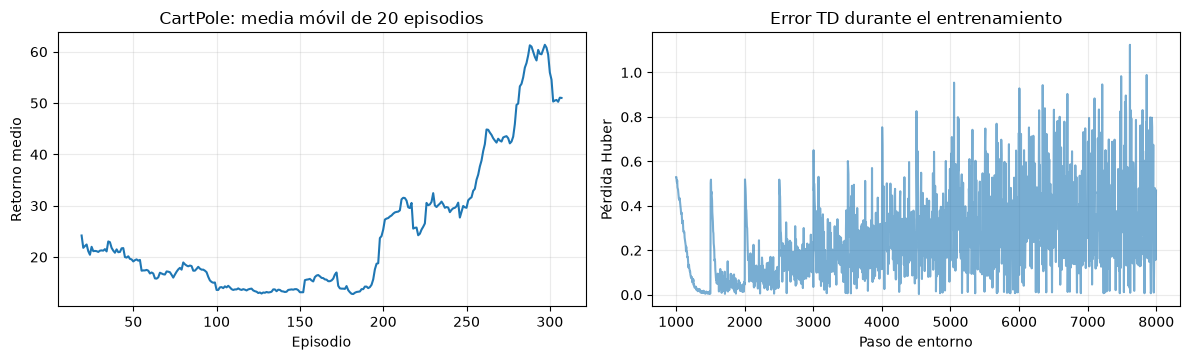

In [9]:
if len(retornos_dqn):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.7))
    ventana = min(20, len(retornos_dqn))
    ax[0].plot(np.arange(ventana-1, len(retornos_dqn)),
               media_movil(retornos_dqn, ventana))
    ax[0].set(xlabel='Episodio', ylabel='Retorno medio',
              title=f'CartPole: media móvil de {ventana} episodios')
    ax[0].grid(alpha=0.25)
    ax[1].plot(perdidas_dqn[:, 0], perdidas_dqn[:, 1], alpha=0.6)
    ax[1].set(xlabel='Paso de entorno', ylabel='Pérdida Huber',
              title='Error TD durante el entrenamiento')
    ax[1].grid(alpha=0.25)
    plt.tight_layout(); plt.show()
else:
    print('Gráficas de DQN disponibles al instalar Gymnasium y entrenar.')

In [10]:
def evaluar_dqn_cartpole(red, semillas=(9001, 9002, 9003, 9004, 9005)):
    if not GYM_DISPONIBLE:
        raise RuntimeError('Gymnasium es necesario para evaluar CartPole.')
    env = gym.make('CartPole-v1')
    resultados = []
    try:
        for semilla in semillas:
            estado, _ = env.reset(seed=semilla)
            retorno = 0.0
            while True:
                accion = accion_dqn(red, estado, epsilon=0.0,
                                   rng=np.random.default_rng(semilla))
                estado, recompensa, terminado, truncado, _ = env.step(accion)
                retorno += recompensa
                if terminado or truncado:
                    break
            resultados.append(retorno)
    finally:
        env.close()
    return np.asarray(resultados, dtype=float)

if red_dqn is not None:
    evaluaciones = evaluar_dqn_cartpole(red_dqn)
    print('Retornos de evaluación:', evaluaciones.tolist())
    print('Media ± DE:', round(evaluaciones.mean(), 2), '±',
          round(evaluaciones.std(ddof=1), 2))
else:
    print('Evaluación pendiente: instala Gymnasium y ejecuta el entrenamiento.')

Retornos de evaluación: [82.0, 93.0, 98.0, 84.0, 103.0]
Media ± DE: 92.0 ± 8.97


## <span style="color:#bd232b">5. Diagnóstico crítico: ¿qué hemos demostrado?</span>

**En la cuadrícula** observamos si la política aprendida alcanza la meta. Como el problema es pequeño, podemos inspeccionar la tabla Q y comprobar su comportamiento. **En CartPole** observamos retornos, pérdidas y evaluaciones separadas. Una pérdida decreciente **no garantiza** una política mejor: el objetivo TD cambia durante el entrenamiento y el aprendizaje por refuerzo no es una regresión supervisada convencional.

Preguntas para discutir:

1. ¿Qué sucede si eliminamos la red objetivo?
2. ¿Qué cambia al reducir el buffer de experiencias a una sola transición?
3. ¿Por qué la evaluación con $\varepsilon>0$ mezcla calidad de política y exploración?
4. ¿Qué diferencia hay entre un episodio terminado por fracaso y uno truncado por duración?
5. ¿Qué resultados necesitaríamos para afirmar que DQN supera una política aleatoria en CartPole?

**Advertencia metodológica:** una única curva de entrenamiento es evidencia ilustrativa, no una comparación estadística concluyente.

## <span style="color:#bd232b">6. Hydro-Lab: del carro con péndulo al control de hidrocarburos</span>

<img src="../Imagenes/arquitectura_laboratorio_G2.4.png" width="820"/>

*Figura 102.4. Arquitectura del laboratorio Hydro-Lab G2.4, reutilizada del proyecto.*

Hydro-Lab es una **red sintética de transporte de hidrocarburos** con cinco nodos y tres bombas (P0, PN y PS). La decisión industrial no consiste en mover un carro a izquierda o derecha: consiste en seleccionar consignas de operación bajo demanda variable, consumo energético y restricciones físicas.

En la interfaz del laboratorio, las consignas físicas de las bombas están en el intervalo **[0.60, 1.00]**. La interfaz de aprendizaje puede utilizar acciones normalizadas antes de convertirlas en consignas. Debemos distinguir las **órdenes** de los **resultados físicos**: un comando de bomba no es directamente un caudal.

La instrumentación de PPO en S2.11 utiliza observaciones vectoriales de **15 componentes** y un espacio de acciones continuas normalizadas de **3 componentes**. El agente no debe recibir información privilegiada del simulador que no esté incluida en sus observaciones.

### 6.1 Por qué DQN no es la elección natural para Hydro-Lab

En CartPole hay dos acciones: $\{\text{izquierda},\text{derecha}\}$. En Hydro-Lab cada decisión puede incluir tres consignas continuas:

$$a_t=(u_{P0,t},u_{PN,t},u_{PS,t})\in[-1,1]^3$$

(en la representación normalizada del agente). Si discretizáramos cada dimensión en $m$ valores, obtendríamos $m^3$ acciones: con $m=11$ serían **1 331 combinaciones** por estado, sin contar restricciones ni la precisión perdida entre niveles. DQN estándar necesitaría estimar un valor para cada combinación.

**Opciones razonables:** (i) discretizar para un experimento de escala pequeña, con limitaciones explícitas; (ii) utilizar métodos para acciones continuas, como PPO, SAC o TD3; (iii) integrar aprendizaje y control/optimización explícita cuando el problema lo requiera.

En este curso, la continuidad pedagógica es: **Q-learning $\to$ DQN $\to$ gradientes de política $\to$ Actor-Crítico $\to$ PPO en Hydro-Lab**.

### 6.2 Actividad de cierre: formular antes de entrenar

**Trabajo en parejas (5 minutos).** Respondan:

1. ¿Qué parte del vector de observación de Hydro-Lab informa sobre demanda, operación y condiciones de la red? ¿Qué información no debería observar el agente?
2. Si la recompensa premia servicio y penaliza energía, ¿cómo evitamos que una política consiga un buen promedio mediante operaciones inseguras?
3. ¿Por qué no basta comparar el retorno de PPO y DQN sin igualar presupuesto, escenarios y semillas?
4. ¿Qué medidas operacionales, además del retorno, exigiría un comité técnico para aceptar un controlador?

**Evidencia de aprendizaje:** un párrafo técnico que explique por qué DQN es apropiado para CartPole pero no es una opción directa para las tres consignas continuas de Hydro-Lab.

**No es necesario modificar Hydro-Lab** para realizar esta actividad.

## <span style="color:#bd232b">7. Ejercicios de profundización</span>

**E1 — Bellman y TD.** Para $Q(s,a)=0.6$, $r=1$, $\gamma=0.9$, $\max_{a'}Q(s',a')=0.8$ y $\alpha=0.2$, calcule el nuevo valor si la transición no es terminal; repita si es terminal.

**E2 — Exploración.** Compare tres valores de $\varepsilon$ y describa cómo cambian los primeros 200 episodios y la política final.

**E3 — Ablación DQN.** Manteniendo la semilla, compare el DQN completo con una versión sin red objetivo. No concluya superioridad a partir de una sola semilla.

**E4 — Evaluación.** Entrene con al menos tres semillas y evalúe cada modelo en un conjunto común de semillas nuevas. Reporte media, desviación estándar y resultados individuales.

**E5 — Acciones continuas.** Calcule el número de combinaciones de acciones para $m=5,11,21$ niveles por bomba; explique la relación entre resolución y costo computacional.

**E6 — Decisión industrial.** Proponga tres indicadores para Hydro-Lab que impidan declarar exitosa una política solo porque su recompensa media es alta.

## <span style="color:#bd232b">8. Pruebas automáticas y reproducibilidad</span>

Las pruebas siguientes verifican propiedades básicas de la cuadrícula, de la tabla Q y del modelo neuronal. La prueba de CartPole se ejecuta solo cuando Gymnasium está instalado. **No sustituyen** la inspección de curvas ni una evaluación experimental con múltiples semillas.

In [11]:
assert q_tabular.shape == (25, 4)
assert np.isfinite(q_tabular).all()
assert len(retornos_q) == 1800
assert exito_voraz, 'La política voraz no alcanzó la meta; revisar la semilla y los hiperparámetros.'
assert recorrido[-1] == entorno.meta
assert np.all(np.isfinite(retornos_q))
assert np.isfinite(perdida_prueba)
assert red_prueba(torch.zeros(2, 4)).shape == (2, 2)
assert 11**3 == 1331
print('Pruebas de integridad: SUPERADAS.')

Pruebas de integridad: SUPERADAS.


## <span style="color:#bd232b">9. Fuentes, figuras, licencia y continuidad editorial</span>

### 9.1 Fuentes directas de la colección Aprendizaje Profundo

- `14_ar_Q_Learning-02.ipynb`: Q-learning y ejemplo FrozenLake; fundamento conceptual del laboratorio tabular.
- `09_ar_DQN_Learning-ver-02.ipynb`: DQN, replay, red objetivo y CartPole; base conceptual de la implementación moderna.
- `05_ar_OpenAI_Gym_CartPole.ipynb`: observaciones, acciones e interacción con CartPole.
- `10_ar_DQN_Learning-Pong.ipynb`: extensión opcional de DQN a Atari; no se ejecuta ni se exige en esta sesión.
- `101_ar_MDP_Fundamentos.ipynb`: prerrequisito sobre MDP y Bellman.
- `Manual_Hydro_Lab_S2.11_G3.1.md`: descripción pedagógica de la red y los controles; documentación del laboratorio.

**Adaptaciones explícitas:** se reemplazan interfaces antiguas de `gym` por Gymnasium; se usa PyTorch en lugar de las implementaciones antiguas de TensorFlow, y se construye un GridWorld autocontenido. Los cuadernos fuente permanecen intactos.

### 9.2 Referencias científicas y técnicas

- Watkins, C. J. C. H. & Dayan, P. (1992). *Q-learning*. Machine Learning, 8, 279–292.
- Mnih, V. et al. (2015). *Human-level control through deep reinforcement learning*. Nature, 518, 529–533.
- Sutton, R. S. & Barto, A. G. (2018). *Reinforcement Learning: An Introduction*, 2.ª ed., MIT Press.
- Farama Foundation. *Gymnasium Documentation*: https://gymnasium.farama.org/
- PyTorch. *Documentation*: https://pytorch.org/docs/stable/

### 9.3 Figuras reutilizadas

Se conservan las rutas relativas del repositorio (`../Imagenes/`): `logo-final-ap.png`, `MDP.png`, `deep_Q_learning.png`, `Ejemplo_polea.gif` y `arquitectura_laboratorio_G2.4.png`. **No se requiere ninguna figura nueva**. Las curvas y el mapa de la cuadrícula se generan en Python. Las figuras preexistentes conservan sus condiciones de autoría y licencia correspondientes.

### 9.4 Licencia MIT: alcance y obligaciones

**Copyright © 2026 Álvaro Montenegro, Daniel Montenegro y Pilar Montenegro — Aprendizaje Profundo.**

El texto, los ejercicios originales y el código nuevo de esta edición se ofrecen bajo la **licencia MIT**, una licencia permisiva que permite usar, copiar, modificar, distribuir, sublicenciar y comercializar, siempre que se conserve el aviso de copyright y la licencia. El texto legal completo debe acompañar al repositorio en un archivo `LICENSE` para facilitar la redistribución.

**Importante:** esta declaración no cambia la licencia de las imágenes, textos, bibliotecas o fragmentos de terceros, ni presupone derechos de licencia sobre material institucional ajeno. Las atribuciones y avisos de terceros deben conservarse. La mención de Universidad de los Andes y Ecopetrol identifica el contexto del curso, no los convierte en titulares de derechos de autor de este cuaderno.

### 9.5 Próxima lección

**Cuaderno 103:** gradientes de política y métodos Actor-Crítico. Allí aprenderemos a parametrizar directamente una política, paso esencial para llegar a PPO y al espacio de acciones continuas de Hydro-Lab.